In [1]:
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import random
import imageio.v3 as iio
import fastplotlib as fpl
from skophys.datasets import ARProcess, ARProcessMovie
from ipywidgets import HBox, VBox

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
locs = np.array([
    [0, 0],
    [2, 0]
])

In [4]:
ar_model = ARProcessMovie(
    n_timepoints=1000,
    n_components=2,
    ar_noise_sigma=0.1,
    obs_noise_sigma=0.1,
    movie_dims=(10, 15),
    component_locs=locs,
    firing_probability=0.02
)

In [5]:
iw = fpl.ImageWidget(ar_model.movie, cmap="viridis", figure_kwargs={"size": (500, 500)})

fig_traces = fpl.Figure(size=(900, 500))

traces_lines = fig_traces[0, 0].add_line_collection(ar_model.traces, colors=["b", "r"])

selector = traces_lines[0].add_linear_selector()

def update_time_index(ev: dict | fpl.GraphicFeatureEvent):
    if isinstance(ev, dict):
        index = ev["t"]
    else:
        index = ev.get_selected_index()

    selector.selection = index
    iw.current_index = {"t": index}

selector.add_event_handler(update_time_index, "selection")
iw.add_event_handler(update_time_index)

HBox([iw.show(), fig_traces.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [6]:
movie = ar_model.movie

In [7]:
movie_mc = movie - movie.mean(axis=0)

In [8]:
from skophys.preprocessing import Vectorizer, UnVectorizer

/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [9]:
X = Vectorizer().transform(movie)
unvec = UnVectorizer(movie.shape[1:])

X_mc = Vectorizer().transform(movie_mc)
unvec = UnVectorizer(movie.shape[1:])

In [10]:
import scipy

## Whiten using mean-centered X acting on non-mean-centered X

In [36]:
Xw = scipy.linalg.pinv(scipy.linalg.sqrtm(X_mc @ X_mc.T / X.shape[1])) @ X

# k: number of components

In [37]:
k = 2

In [38]:
X_init = Xw

In [39]:
cov = X_init.T @ X_init

XTX = cov / np.linalg.norm(cov, ord="fro")

T = XTX.shape[0]

In [40]:
iw_cov = fpl.ImageWidget(XTX[:200, :200], cmap="viridis", figure_kwargs={"size": (600, 600)})
fig = fpl.Figure(size=(600, 300))
fig[0, 0].add_line_collection(ar_model.traces, colors=["r", "b"])

VBox([iw_cov.show(), fig.show(maintain_aspect=False)])

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


RFBOutputContext()

In [41]:
eta = 0.5

In [42]:
from tqdm.notebook import tqdm

In [43]:
from pathlib import Path
from scipy.sparse.linalg import svds
from sklearn.decomposition import randomized_svd

In [44]:
k = 2

In [45]:
def nnsvd(A, k, eps: float = 1e-6):
    U, S, V = randomized_svd(A, n_components=k, n_iter=15)
    W = np.zeros_like(U)
    H = np.zeros_like(V)
    
    # The leading singular triplet is non-negative
    # so it can be used as is for initialization.
    W[:, 0] = np.sqrt(S[0]) * np.abs(U[:, 0])
    H[0, :] = np.sqrt(S[0]) * np.abs(V[0, :])
    
    for j in range(1, k):
        x, y = U[:, j], V[j, :]
    
        # extract positive and negative parts of column vectors
        x_p, y_p = np.maximum(x, 0), np.maximum(y, 0)
        x_n, y_n = np.abs(np.minimum(x, 0)), np.abs(np.minimum(y, 0))
    
        # and their norms
        x_p_nrm, y_p_nrm = np.linalg.norm(x_p, ord=2), np.linalg.norm(y_p, ord=2)
        x_n_nrm, y_n_nrm = np.linalg.norm(x_n, ord=2), np.linalg.norm(y_n, ord=2)
    
        m_p, m_n = x_p_nrm * y_p_nrm, x_n_nrm * y_n_nrm
    
        # choose update`
        if m_p > m_n:
            u = x_p / x_p_nrm
            v = y_p / y_p_nrm
            sigma = m_p
        else:
            u = x_n / x_n_nrm
            v = y_n / y_n_nrm
            sigma = m_n
    
        lbd = np.sqrt(S[j] * sigma)
        W[:, j] = lbd * u
        H[j, :] = lbd * v
    
    W[W < eps] = 0
    H[H < eps] = 0
    
    return W, H    

_, Y = nnsvd(XTX, k)

<Axes: >

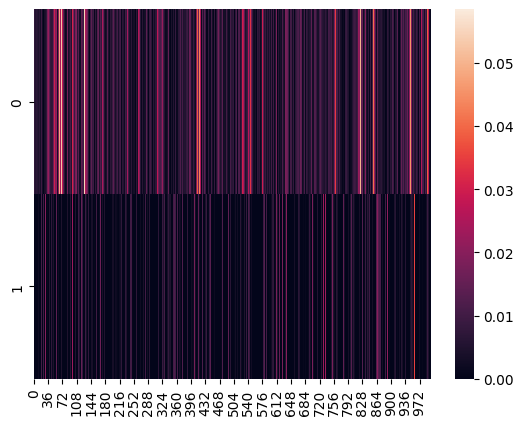

In [46]:
sns.heatmap(Y)

RFBOutputContext()

JupyterRenderCanvas(css_height='600.0px', css_width='300.0px')
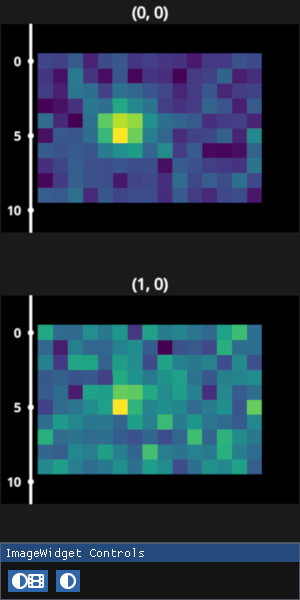

In [47]:
W = Y @ X_init.T

images = list()
for k_i in range(k):
    images.append(unvec.transform(W[k_i, :].T))
    # titles.append(f"k_{k_i}, l_{l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    # names=titles,
    figure_shape=(2, 1),
    figure_kwargs={"size": (300, 600)},
    histogram_widget=False,
)

iw_W.show()

In [48]:
# Ys = list()

# Y = (np.random.randn(k, T) / np.sqrt(T))

# Y /= Y.max()
# Y *= X.max()

for iteration in tqdm(range(1_000)):
    # Ys.append(Y)
    Y_old = Y
    Y = Y + eta * Y @ (XTX - Y.T @ Y)

    zeroed = Y.sum(axis=1) == 0.0
    Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)
    
    Y = Y.clip(0)

    er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta

    if er < 1e-3:
        break

  0%|          | 0/1000 [00:00<?, ?it/s]

In [38]:
er

0.004407045019657751

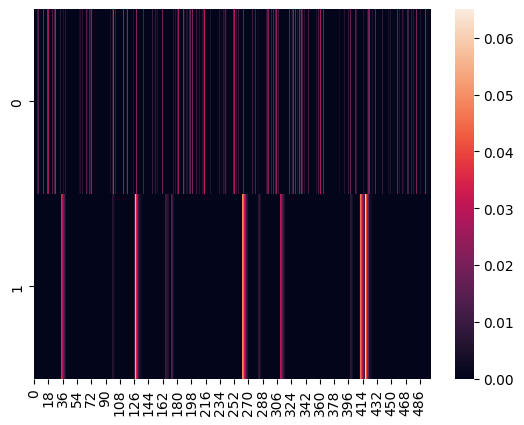

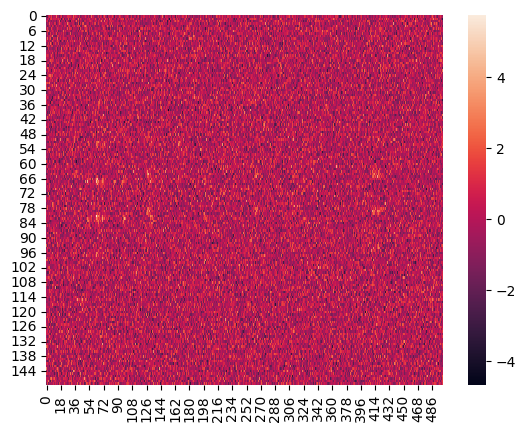

In [39]:
sns.heatmap(Y[:, :500])
plt.show()

sns.heatmap(X_init[:, :500])
plt.show()

In [40]:
W = Y @ X_init.T #/ sum_y_squared
M = Y @ Y.T #/ sum_y_squared

In [41]:
W.shape

(2, 150)

In [42]:
Y.shape

(2, 1000)

<Axes: >

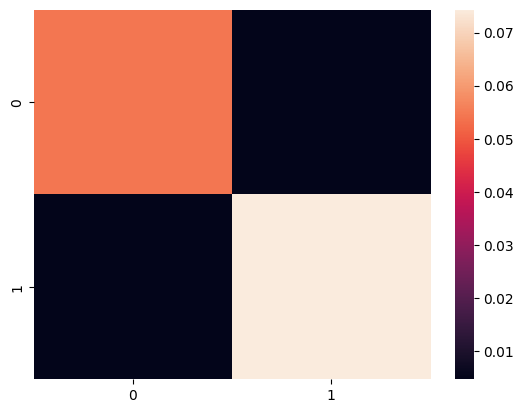

In [43]:
sns.heatmap(M)

In [44]:
np.linalg.eigvals(M)

array([0.05335394, 0.075365  ])

In [45]:
from itertools import product

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='1000.0px', css_width='800.0px')
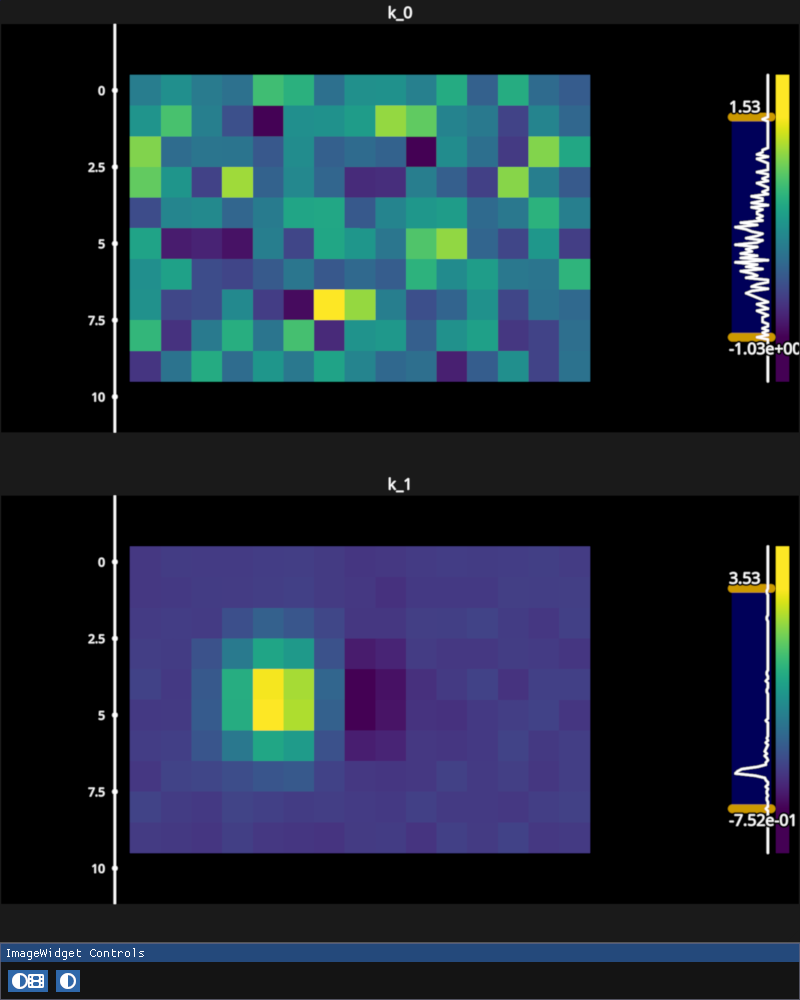

In [46]:
# make images by reshaing each lag within `W`
images, titles = list(), list(),
for k_i in range(k):
    images.append(unvec.transform(W[k_i, :].T))
    titles.append(f"k_{k_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(k, 1),
    figure_kwargs={"size": (800, 1000)},
)

iw_W.show()